# Radiomics preprocessing, modeling and evaluation

This notebook documents ... title... TODO after i have done the rest, i still am not sure if i will create another notebook.

The LIDC annotations first come from `annotations_all.csv`. We use `src/clean_lidc_annotations.py` to exclude nodules that have more than 4 annotations associated with them by the clustering algorithm provided by Pylidc. The cleaned dataset is then saved to `data/processed/lidc_annotations_clean.csv`.

The LNDb annotations come from `allNods.csv` and o`chars_trainNodules.csv`, files provided directly by the dataset authors.

A configuration file is provided `configs/paths.yaml`, to set the file paths that match the ones on your machine.

PyLIDC reads the LIDC DICOM folder from `~/.pylidcrc`. Set this path before running LIDC feature extraction or the image examples in the EDA notebook.

For LNDb, `allNods.csv` shows which annotations belong to the same nodule and whether each reader considered the finding a nodule. `chars_trainNodules.csv` provides the individual malignancy ratings. This allows us to group the ratings by nodule and calculate our own mean, median, and mode. 

In [2]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "configs/paths.yaml").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.radiomics_extraction import load_paths
from src.malignancy import prepare_lndb_annotations, aggregate_ratings, create_targets

paths = load_paths(ROOT / "configs/paths.yaml")

lidc = pd.read_csv(paths["lidc"]["annotations"])
lndb = prepare_lndb_annotations(
    pd.read_csv(paths["lndb"]["characteristics"]),
    pd.read_csv(paths["lndb"]["findings"]),
)

## 1. Combine the reader ratings

Each nodule can have several malignancy ratings, but a model needs one target per nodule. We compare the mean, median and mode. When the mode is tied, we leave it missing.

For LNDb, we keep both the full dataset and the subset with segmentation masks. In `allNods.csv`, `DiamEq_Rad = 3` marks nodules smaller than 3 mm annotated as points rather than masks. These are excluded only from the segmented subset.

The following table shows how many nodules each method places below, at or above 3, and how many have no unique value.

In [3]:
nodules = {
    "LIDC": aggregate_ratings(lidc, ["patient_id", "series_uid", "nodule_id"]),
    "LNDb, all sizes": aggregate_ratings(lndb, ["LNDbID", "NoduleID"]),
    "LNDb, segmented": aggregate_ratings(
        lndb[lndb["DiamEq_Rad"] > 3], ["LNDbID", "NoduleID"]
    ),
}

rows = []
for dataset, table in nodules.items():
    for method in ["mean", "median", "mode"]:
        values = table[f"malignancy_{method}"]
        rows.append({
            "dataset": dataset, "method": method,
            "nodules": len(table),
            "below 3": values.lt(3).sum(),
            "equal to 3": values.eq(3).sum(),
            "above 3": values.gt(3).sum(),
            "no unique value": values.isna().sum(),
        })

display(pd.DataFrame(rows).set_index(["dataset", "method"]))

nodules  below 3  equal to 3  above 3  no unique value
dataset         method                                                        
LIDC            mean       2637     1363         641      633                0
                median     2637     1149         952      536                0
                mode       2637      801         919      365              552
LNDb, all sizes mean        765      512         161       92                0
                median      765      505         171       89                0
                mode        765      430         155       68              112
LNDb, segmented mean        622      380         151       91                0
                median      622      373         161       88                0
                mode        622      299         145       67              111

## 2. Define the targets

The mode will not be used because ties leave many nodules without a unique target.

For binary classification, nodules with an aggregated malignancy value of 3 are commonly removed because they are considered indeterminate. Section 2 of [Baltatzis et al. (2021)](https://arxiv.org/abs/2108.05386) describes this as a common LIDC data-curation step.

Our results show the same pattern reported in Section 2 of [Baltatzis et al. (2021)](https://arxiv.org/html/2108.05386#S2): the median produces more nodules with an indeterminate value of 3 than the mean. The authors explain that excluding these nodules results in “a smaller, more balanced dataset, which is much easier to separate based on the key characteristic of nodule diameter.” Our comparison confirms the difference in indeterminate counts and so we think its better to keep the most amount of information possible for our mdoels to learn.

We also thought of creating a regression model, which could take advantage of all the data because it doesn't need to remove nodules with a rating of 3, so we keep both the mean and the median for it.

- `target_regression_mean`: the mean rating, without rounding.
- `target_regression_median`: the median rating, without rounding.
- `target_classification_mean`: the mean rounded to an integer from 1 to 5. Half values are rounded upwards, for example 2.5 → 3 and 3.5 → 4.
- `target_binary_mean`: 0 when the unrounded mean is below 3 and 1 when it is above 3. Nodules with a mean exactly equal to 3 are excluded from this task only.

In [4]:
targets = {
    name: create_targets(table)
    for name, table in nodules.items()
}

example = targets["LNDb, all sizes"]
columns = ["ratings"] + example.filter(like="target_").columns.tolist()
display(example[columns].head())

,ratings,target_regression_mean,target_regression_median,target_classification_mean,target_binary_mean
0,"[2.0, 2.0, 2.0]",2.0,2.0,2,0
1,[2.0],2.0,2.0,2,0
2,"[1.0, 1.0, 1.0]",1.0,1.0,1,0
3,"[1.0, 1.0]",1.0,1.0,1,0
4,"[3.0, 2.0]",2.5,2.5,3,0


### Target distributions

In [5]:
counts = pd.DataFrame({
    name: {
        "nodules": len(table),
        **{
            f"class {k}": table["target_classification_mean"].eq(k).sum()
            for k in range(1, 6)
        },
        "binary 0": table["target_binary_mean"].eq(0).sum(),
        "binary 1": table["target_binary_mean"].eq(1).sum(),
        "binary excluded": table["target_binary_mean"].isna().sum(),
    }
    for name, table in targets.items()
}).T

display(counts)

,nodules,class 1,class 2,class 3,class 4,class 5,binary 0,binary 1,binary excluded
LIDC,2637,286,608,1249,384,110,1363,633,641
"LNDb, all sizes",765,213,254,209,71,18,512,92,161
"LNDb, segmented",622,138,197,199,70,18,380,91,151


### Save the targets

In [6]:
output_paths = {
    "LIDC": paths["lidc"]["targets"],
    "LNDb, all sizes": paths["lndb"]["targets"],
    "LNDb, segmented": paths["lndb"]["segmentation_targets"],
}

for name, path in output_paths.items():
    table = targets[name]
    ids = (
        ["patient_id", "series_uid", "nodule_id"]
        if name == "LIDC" else ["LNDbID", "NoduleID"]
    )
    columns = ids + ["ratings"] + table.filter(like="target_").columns.tolist()
    path.parent.mkdir(parents=True, exist_ok=True)
    table[columns].to_csv(path, index=False)

## 3. Patient-level folds

The smallest integer class limits how many stratified folds can be created. LNDb has only 18 class-5 nodules, so we use five folds. LIDC has 110 class-5 nodules and a much larger dataset, so we use ten folds.

We split by patient to prevent data leakage. `StratifiedGroupKFold` keeps every patient in one fold while approximately preserving `target_classification_mean` ([scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)). Because patients can have several nodules, exact class balance is not guaranteed and is checked below. The same fold assignments are reused for every target and model.

We create the LNDb folds once using all 765 nodules. The 622-nodule segmented subset keeps the same patient assignments rather than being split again. This keeps the comparisons consistent, although removing smaller nodules can change the class distribution within each fold.

In [7]:
from src.splitting import create_patient_folds

lidc_folds = create_patient_folds(
    targets["LIDC"], "patient_id", "target_classification_mean", n_splits=10
)

lndb_folds = create_patient_folds(
    targets["LNDb, all sizes"], "LNDbID", "target_classification_mean", n_splits=5
)

In [8]:
#LIDC
lidc_folded = targets["LIDC"].merge(
    lidc_folds, on="patient_id", how="left", validate="many_to_one"
)

lidc_counts = pd.crosstab(
    lidc_folded["fold"], lidc_folded["target_classification_mean"]
)
lidc_counts.insert(0, "patients", lidc_folded.groupby("fold")["patient_id"].nunique())
display(lidc_counts)

target_classification_mean,patients,1,2,3,4,5
fold,,,,,,
1,86,18,56,118,37,11
2,84,37,37,115,50,7
3,87,18,63,126,47,15
4,90,33,70,138,34,17
5,87,31,61,110,32,11
6,87,22,66,115,40,9
7,84,17,56,116,40,6
8,88,40,72,132,46,9
9,88,39,56,130,31,15


In [9]:
#LNDB
lndb_folded = targets["LNDb, all sizes"].merge(
    lndb_folds, on="LNDbID", how="left", validate="many_to_one"
)

lndb_counts = pd.crosstab(
    lndb_folded["fold"], lndb_folded["target_classification_mean"]
)
lndb_counts.insert(0, "patients", lndb_folded.groupby("fold")["LNDbID"].nunique())
display(lndb_counts)

target_classification_mean,patients,1,2,3,4,5
fold,,,,,,
1,44,41,57,40,18,2
2,48,47,48,44,18,2
3,39,40,47,34,7,6
4,42,47,47,48,17,2
5,39,38,55,43,11,6


In [10]:
#LNDB segmented
lndb_ge3_folded = targets["LNDb, segmented"].merge(
    lndb_folds, on="LNDbID", how="left", validate="many_to_one"
)

lndb_ge3_counts = pd.crosstab(
    lndb_ge3_folded["fold"], lndb_ge3_folded["target_classification_mean"]
)
lndb_ge3_counts.insert(
    0, "patients", lndb_ge3_folded.groupby("fold")["LNDbID"].nunique()
)
display(lndb_ge3_counts)

target_classification_mean,patients,1,2,3,4,5
fold,,,,,,
1,41,30,47,37,18,2
2,47,28,37,43,18,2
3,37,27,37,33,7,6
4,42,29,36,45,16,2
5,37,24,40,41,11,6


In [11]:
assert lidc_folds["patient_id"].is_unique
assert lndb_folds["LNDbID"].is_unique

assert lidc_folded["fold"].notna().all()
assert lndb_folded["fold"].notna().all()
assert lndb_ge3_folded["fold"].notna().all()

assert set(lidc_folds["fold"]) == set(range(1, 11))
assert set(lndb_folds["fold"]) == set(range(1, 6))

### Save the patient folds

Each CSV contains the patient identifier and its fold number. Both LNDb populations use the same patient-fold file.

In [12]:
for dataset, table in [("lidc", lidc_folds), ("lndb", lndb_folds)]:
    path = paths[dataset]["folds"]
    path.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(path, index=False)

## 4. Radiomics extraction

We extract features using single-slice 2D, five-slice 2.5D and full-volume 3D approaches. The extraction choices and supporting EDA are explained in [radiomics_decisions_eda.ipynb](radiomics_decisions_eda.ipynb).

Run the extraction scripts from the project root. For example, these commands extract single-slice circle features using the dataset-specific P95 radii: 14 mm for LIDC and 6 mm for LNDb.

```bash
uv run python LIDCfeatureExtraction.py --roi circle --radius 14
uv run python LNDBfeatureExtraction.py --roi circle --radius 6
```

The scripts read the paths from `configs/paths.yaml` and select the YAML configuration for the extraction method. These commands produce `lidc_circle_r14_hu.csv` and `lndb_circle_r6_hu.csv` in the configured output folder.

The scripts support different regions, numbers of slices, radii, consensus levels, bin widths and HU clipping. Run either script with `-h` or `--help` to see the available options.

| Decision | What we used or compared | Reason |
|---|---|---|
| Image values | Original HU and clipping to `[-1000, 400]` | Check whether a range used in neural-network preprocessing also helps radiomics. |
| Normalization | `normalize: false` | Keep the intensity values in HU. |
| Pixel spacing | 0.7 × 0.7 mm for 2D | Use a common spacing close to both datasets’ median values. |
| Interpolation | B-spline for images and nearest neighbour for masks | Resample the images while preserving mask labels. |
| Circle radius | P95, P97 and P99, rounded upwards | Use nodule-size percentiles to suggest radii, testing shared and dataset-specific values. |
| Slice selection | Nearest slice to the centroid for circles, largest mask-area slice for segmentations | Define which axial slice each 2D method uses. |
| Mask consensus | 25%, 50%, 75% and 100% | Compare different levels of agreement between readers. |
| Bin width | 10 and 25 HU | The 50 HU example produced few bins, so we left it out to avoid another extraction run. |
| Feature families | Intensity and texture features, with shape features for segmentation masks | Describe the image values, their spatial patterns and the nodule’s geometry. |
| 2.5D extension | Five adjacent slices, with prediction weights 1, 2, 3, 2, 1 | Include neighbouring slices while giving more importance to the central slices. |
| 3D extension | Full spheres or segmentation volumes, isotropic spacing, LoG and LBP3D | Extend extraction to volumetric information. |

## 5. Modeling

We use `src/modeling.py` to train and evaluate classification models using the extracted features, target tables and saved patient folds. For example, the following command trains a class-weighted Random Forest using the circle features generated above:

```bash
uv run python -m src.modeling \
  --lidc data/lidc_circle_r14_hu.csv \
  --lndb data/lndb_circle_r6_hu.csv \
  --model rf \
  --class-weight balanced \
  --output models/rf_circle_p95_reproduction
```

Each run saves the model, validation predictions and metrics under its output folder. Use a different output folder for each experiment. Run the script with `-h` or `--help` to see the options for balancing, feature selection, tuning and other models.

The following tables summarise what helped in the tested configurations. The comparisons are in [radiomics_experiments.ipynb](radiomics_experiments.ipynb).

| Choice | Main finding |
|---|---|
| Circle radius | P95 performed better than P99. Using 11 mm for LIDC and 6 mm for LNDb gave similar results to P95. |
| HU clipping | Did not help the tested circle RF. |
| 2D segmentation versus circles | Segmentation improved rating agreement, with similar balanced accuracy. |
| Mask consensus | 50% gave the strongest reported results. Higher consensus also excluded more nodules. |
| Five-slice 2.5D | Did not improve the tested circle RF. |
| 3D spheres versus 2D circles | Spheres improved rating agreement, but slightly reduced balanced accuracy. |
| 3D versus 2D segmentation | 3D improved balanced accuracy, with slightly lower rating agreement. |
| 3D segmentation versus spheres | Segmentation performed better in the matched RF comparison. |
| Bin width | 25 HU performed better than 10 HU for the tested circles. |


| Choice | Main finding |
|---|---|
| Adding LIDC | Made little difference compared with training on LNDb alone in the tested circle models. |
| Class weights | Improved class recall for circles, but increased rating errors. |
| SMOTE | Improved balanced accuracy over class weights, but increased rating errors. |
| Balanced Random Forest | Had the highest balanced accuracy among the balancing methods, but larger rating errors. |
| Top-k selection | Helped the sphere RF. It did not improve balanced accuracy for the tested circles or segmentations. |
| Original-only features | Did not improve the tested circle models. |
| Normalized feature pairs | Small, inconsistent improvements. |
| XGBoost | Beat Balanced RF for circles. For 3D regions, neither won on every metric. |
| RF tuning | Made little difference in the tested circle RF. |

## 6. Evaluation

We found duplicate CT scans with different IDs in the LNDb dataset ([section 7](radiomics_decisions_eda.ipynb#7-repeated-lndb-ct-scans)), but because we had already started analysing the results, we decided to prioritize other parts of the project rather than retraining all the models without these copies.

We confirmed 11 identical CT pairs, with ten assigned to different folds. Given the small number, we believe the evaluation is not too far from the true performance, although we have not measured their effect.

The binary models are our main focus, for the reasons explained below. The newer binary experiments exclude these copies.

### 6.1 Five-class classification

We compare extraction settings and training choices using:

- **Balanced accuracy:** average recall of the five classes. Higher is better.
- **Macro F1:** balances precision and recall, giving every class equal importance. Higher is better.
- **QWK:** agreement that accounts for the distance between classes. Higher is better.
- **MAE:** average absolute class error. Lower is better.
- **Combined score** = [balanced accuracy + macro F1 + QWK + (1 − MAE)] / 4. Higher is better.

#### Spheres versus segmentation — 622 shared nodules

These models use the same evaluation nodules and matched training settings. Segmentation has the higher combined score in all four comparisons, although spheres sometimes have higher balanced accuracy.

Source: [experiments section 8.2](radiomics_experiments.ipynb#82-spheres-versus-segmentation-on-shared-nodules) → [`radiomics_region_comparison.csv`](../data/processed/radiomics_region_comparison.csv).

In [13]:
region_comparison = pd.read_csv(ROOT / "data/processed/radiomics_region_comparison.csv")
display(region_comparison.set_index(["model", "region"])[[
    "balanced accuracy", "macro F1", "QWK", "MAE", "combined score",
]].round(3))

balanced accuracy  macro F1    QWK  \
model                  region                                             
Class-weighted RF      Sphere                    0.401     0.428  0.475   
                       Segmentation              0.428     0.446  0.523   
RF + SMOTE             Sphere                    0.452     0.436  0.500   
                       Segmentation              0.445     0.435  0.504   
Balanced RF            Sphere                    0.484     0.385  0.477   
                       Segmentation              0.480     0.416  0.519   
Class-weighted XGBoost Sphere                    0.442     0.410  0.502   
                       Segmentation              0.455     0.430  0.529   

                                       MAE  combined score  
model                  region                               
Class-weighted RF      Sphere        0.680           0.406  
                       Segmentation  0.632           0.441  
RF + SMOTE             Sphere        0.722           0.416  
                       Segmentation  0.698           0.422  
Balanced RF            Sphere        0.788           0.389  
                       Segmentation  0.743           0.418  
Class-weighted XGBoost Sphere        0.725           0.407  
                       Segmentation  0.712           0.425

#### Competition comparison — 765 nodules

The table shows the five highest combined scores on the same 765 LNDb nodules. The sphere RF with SMOTE ranked first and is our strongest competition candidate among these runs.

Source: [experiments section 8.1](radiomics_experiments.ipynb#81-five-class-table-for-the-main-notebook) -> [`radiomics_five_class_results.csv`](../data/processed/radiomics_five_class_results.csv).

In [14]:
five_class_results = pd.read_csv(ROOT / "data/processed/radiomics_five_class_results.csv")
display(five_class_results.set_index("model")[[
    "balanced accuracy", "macro F1", "QWK", "MAE", "combined score",
]].head(5).round(3))

,balanced accuracy,macro F1,QWK,MAE,combined score
model,,,,,
"RF + SMOTE, sphere",0.458,0.429,0.539,0.672,0.439
"RF + SMOTE + auxiliary targets, sphere",0.449,0.424,0.528,0.678,0.430
"Class-weighted RF, sphere, top 100",0.407,0.428,0.513,0.654,0.423
"RF + SMOTE, sphere, GLDM features",0.438,0.412,0.504,0.697,0.414
"RF + SMOTE, sphere, intensity features",0.436,0.406,0.514,0.702,0.414


### 6.2 Binary

This is our main model, which we believe is closer to what could be used in a real clinical context, for several reasons.

- The 1–5 ratings used to train our models are very subjective, and radiologists do not always agree. Imagine a nodule given a rating of 1 by one radiologist and 5 by another, a real example from LIDC. Taking the mean gives 3, which we exclude from binary training. This lets the model train without these indeterminate cases.

- According to lecure given by [Hélder P. Oliveira](https://www.inesctec.pt/en/people/helder-filipe-oliveira), a renowned researcher in lung cancer, radiologists already identify benign nodules well and quickly, and need more help deciding whether a nodule could be malignant. This is where our model enters. Our aim is 0 FN, meaning no malignatn nodules are predicted as benign, providing additional support to the radiologist.

The target is reader mean >3 versus <3, excluding means of exactly 3.

We compare accuracy, balanced accuracy, macro F1, recall, specificity, precision and AUC, together with FN and FP. Our priority remains reducing FN.

#### Default decisions

First, we compare the default decisions on the same 471 nodules, including 91 positives. These historical runs include the duplicate CT copies.

Accuracy is above 80%, but the models still miss 33–47 positives.

Source: [experiments section 11.1](radiomics_experiments.ipynb#111-default-decisions) → [`radiomics_binary_default_results.csv`](../data/processed/radiomics_binary_default_results.csv).

In [15]:
binary_default = pd.read_csv(ROOT / "data/processed/radiomics_binary_default_results.csv")
display(binary_default.set_index("model")[[
    "FN", "FP", "accuracy", "balanced accuracy", "macro F1",
    "recall", "specificity", "precision", "AUC",
]].round(3))

,FN,FP,accuracy,balanced accuracy,macro F1,recall,specificity,precision,AUC
model,,,,,,,,,
XGBoost,33,49,0.826,0.754,0.738,0.637,0.871,0.542,0.881
Balanced RF,34,53,0.815,0.743,0.725,0.626,0.861,0.518,0.865
"RF, intensity only",47,27,0.843,0.706,0.724,0.484,0.929,0.620,0.872


#### Average nodule radius: readers and XGBoost

The graph compares the average radius of nodules grouped as negative or positive by the readers and by baseline XGBoost.

Radius is calculated from the segmentation volume using a sphere with the same volume. The comparison uses the same 459 nodules, with confirmed CT copies excluded.

Sources: [`3D segmentation features`](../data/lndb_ge3_segmentation_3d_c50_hu.csv) and the saved predictions in `models/segmentation_binary_calibration/validation_predictions.csv`.

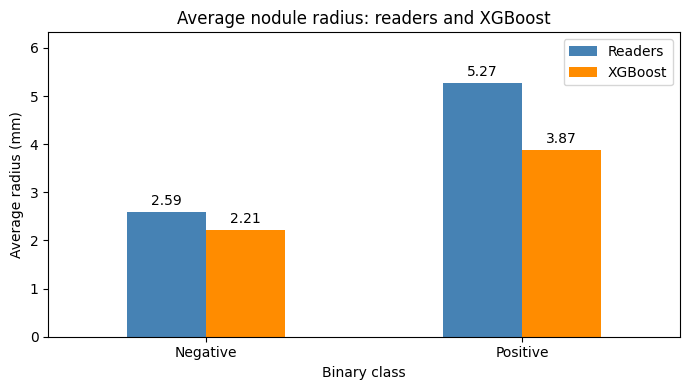

In [24]:
import matplotlib.pyplot as plt
saved = pd.read_csv(
    ROOT / "models/segmentation_binary_calibration/validation_predictions.csv"
)
predictions = saved.loc[
    saved["model"].eq("Binary XGBoost, all features")
]

keys = ["LNDbID", "FindingID"]
radius_data = size_data[keys + ["target_binary_mean"]].copy()
radius_data["radius (mm)"] = radius

radius_data = radius_data.merge(
    predictions[keys + ["prediction"]],
    on=keys,
    validate="one_to_one",
)
assert len(radius_data) == len(size_data)

mean_radius = pd.DataFrame({
    "Readers": radius_data.groupby("target_binary_mean")["radius (mm)"].mean(),
    "XGBoost": radius_data.groupby("prediction")["radius (mm)"].mean(),
}).reindex([0, 1])

ax = mean_radius.plot.bar(
    figsize=(7, 4), rot=0, color=["steelblue", "darkorange"],
)
ax.set_xticklabels(["Negative", "Positive"])
ax.set_xlabel("Binary class")
ax.set_ylabel("Average radius (mm)")
ax.set_title("Average nodule radius: readers and XGBoost")

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_ylim(0, mean_radius.max().max() * 1.2)
plt.tight_layout()
plt.show()

#### Does removing size-related features help?

We compare XGBoost and Balanced RF using three settings:

- **No filter:** keep all features.
- **Filter 0.9:** remove features with correlation strength above 0.9 with maximum 3D diameter.
- **Filter 0.7:** remove features above 0.7, so more features are removed.

These cutoffs were chosen to test, not calculated from the graphs. We remove features, not nodules. Size may contain useful information, so filtering is not necessarily an improvement.

This comparison changes only the feature filter, without parameter tuning. All rows use the same 459 nodules. Each filter is calculated using training data only, and alert thresholds are chosen on separate calibration folds.

Source: saved `validation_predictions.csv` files in the three run folders listed below.

In [23]:
from sklearn.metrics import f1_score, roc_auc_score
from src.binary_evaluation import binary_metrics

filter_runs = {
    "No filter": "segmentation_binary_calibration",
    "Filter 0.9": "segmentation_binary_diameter09",
    "Filter 0.7": "segmentation_binary_diameter07",
}
model_names = {
    "Binary XGBoost, all features": "XGBoost",
    "Binary Balanced RF, all features": "Balanced RF",
}

keys = ["LNDbID", "FindingID"]
reference = size_data.set_index(keys)[[
    "fold", "target_binary_mean",
]].sort_index()

rows = []
for variant, run in filter_runs.items():
    saved = pd.read_csv(
        ROOT / "models" / run / "validation_predictions.csv"
    )
    for recipe, name in model_names.items():
        predictions = saved.loc[saved.model.eq(recipe)].set_index(keys).sort_index()
        pd.testing.assert_frame_equal(
            reference, predictions[reference.columns], check_dtype=False,
        )

        target = predictions["target_binary_mean"]
        predicted = predictions["prediction"]
        rows.append({
            "model": name,
            "filter": variant,
            **binary_metrics(target, predicted),
            "macro F1": f1_score(
                target, predicted, average="macro", zero_division=0,
            ),
            "AUC": roc_auc_score(target, predictions["score"]),
        })

filter_results = pd.DataFrame(rows).rename(columns={
    "balanced_accuracy": "balanced accuracy",
    "sensitivity": "recall",
})
display(filter_results.set_index(["model", "filter"])[[
    "FN", "FP", "accuracy", "balanced accuracy", "macro F1",
    "recall", "specificity", "precision", "AUC",
]].round(3))

,,FN,FP,accuracy,balanced accuracy,macro F1,recall,specificity,precision,AUC
model,filter,,,,,,,,,
XGBoost,No filter,4,161,0.641,0.761,0.608,0.953,0.570,0.335,0.877
Balanced RF,No filter,3,212,0.532,0.699,0.517,0.965,0.433,0.279,0.859
XGBoost,Filter 0.9,6,146,0.669,0.770,0.630,0.929,0.610,0.351,0.875
Balanced RF,Filter 0.9,3,204,0.549,0.710,0.532,0.965,0.455,0.287,0.861
XGBoost,Filter 0.7,4,180,0.599,0.736,0.573,0.953,0.519,0.310,0.876
Balanced RF,Filter 0.7,2,212,0.534,0.705,0.520,0.976,0.433,0.281,0.862


The 0.7 filter helped Balanced RF detect one more positive, but did not improve XGBoost. We therefore kept baseline XGBoost with all features, which had the fewest false positives among the plotted zero-FN points.

#### ROC and model selection

The curves compare the baseline and filtered/tuned models on the same 459 nodules, including 85 positives. Confirmed CT copies were excluded before training, calibration and evaluation.

For each curve, the marked threshold detects all 85 positives in the plotted predictions.

The ROC shows the original models and the models with the 0.7 filter and tuning. We want to miss no positive nodules. At the points where none were missed, the original XGBoost gave the fewest false alarms.

These thresholds were selected using the plotted evaluation scores. The zero-FN result therefore applies to these evaluated predictions.

Source: [experiments section 11.8](radiomics_experiments.ipynb#118-duplicate-excluded-roc-for-the-main-notebook) → [`ROC figure`](../data/processed/radiomics_binary_roc.png) and [`radiomics_binary_roc_points.csv`](../data/processed/radiomics_binary_roc_points.csv).

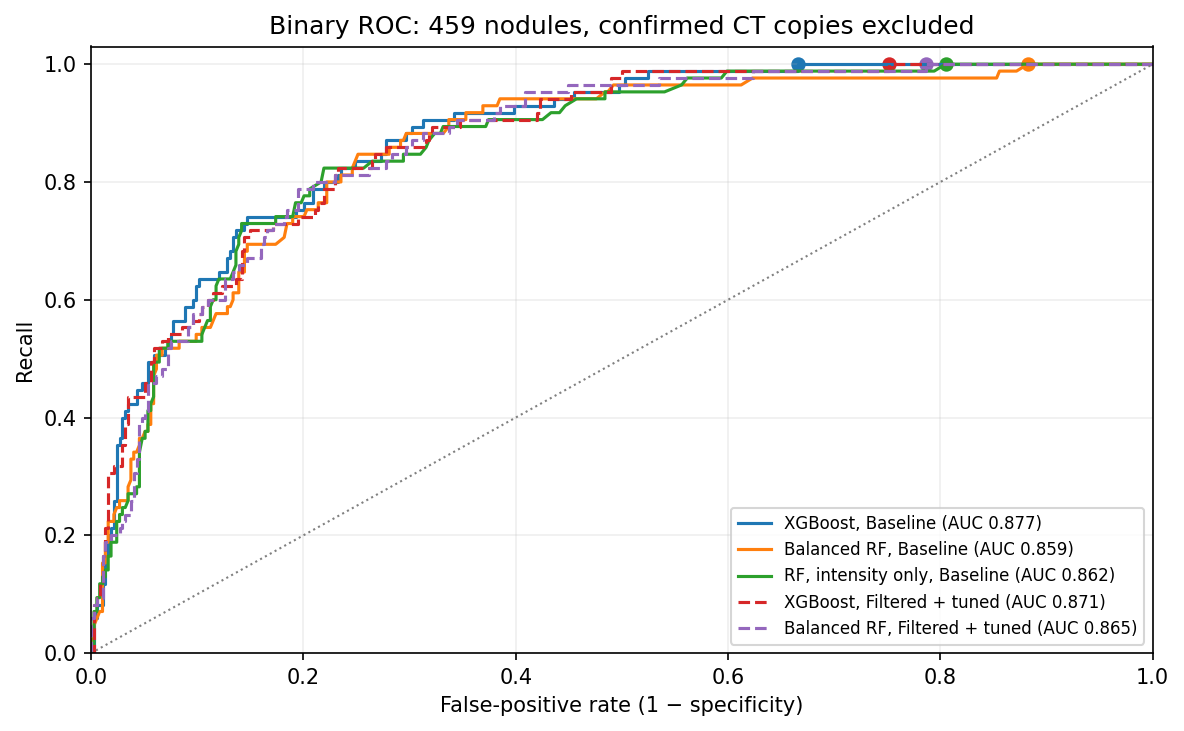

,,threshold,FN,FP,accuracy,balanced accuracy,macro F1,recall,specificity,precision,AUC
model,variant,,,,,,,,,,
XGBoost,Baseline,0.0168,0,249,0.4575,0.6671,0.4534,1.0,0.3342,0.2545,0.8771
Balanced RF,Baseline,0.0620,0,330,0.2810,0.5588,0.2753,1.0,0.1176,0.2048,0.8586
"RF, intensity only",Baseline,0.0440,0,301,0.3442,0.5976,0.3438,1.0,0.1952,0.2202,0.8617
XGBoost,Filtered + tuned,0.0255,0,281,0.3878,0.6243,0.3876,1.0,0.2487,0.2322,0.8707
Balanced RF,Filtered + tuned,0.0823,0,294,0.3595,0.6070,0.3594,1.0,0.2139,0.2243,0.8650


Selected: XGBoost — Baseline
Threshold: 0.016774


In [27]:
import pandas as pd
from IPython.display import Image, display

roc_points = pd.read_csv(
    ROOT / "data/processed/radiomics_binary_roc_points.csv"
)

display(Image(
    filename=str(ROOT / "data/processed/radiomics_binary_roc.png")
))

display(roc_points.set_index(["model", "variant"])[[
    "threshold", "FN", "FP", "accuracy", "balanced accuracy",
    "macro F1", "recall", "specificity", "precision", "AUC",
]].round(4))

# Select the point with the fewest false positives while keeping zero FN.
selected_model = (
    roc_points.loc[roc_points["FN"].eq(0)]
    .sort_values("FP")
    .iloc[0]
)

print(f"Selected: {selected_model['model']} — {selected_model['variant']}")
print(f"Threshold: {selected_model['threshold']:.6f}")

### 6.3 Regression

The Regression model we used was linear regression with L2/Ridge regularization, 

We compare it by rounding his prediction to the binary and to the 5 classes problem.

We got no clear improvements.

The table compares continuous errors and QWK after rounding to five classes on the same 622 nodules.

On the historical 471-nodule alert comparison, segmentation Ridge missed 60 of 88 nodules rated 4–5 after rounding, or 38 when using a continuous prediction above 3 as an alert. The detailed conversions are in [experiments section 7](radiomics_experiments.ipynb#7-does-regression-provide-useful-alerts).

Source: [experiments section 7.1](radiomics_experiments.ipynb#71-regression-table-for-the-main-notebook) → [`radiomics_regression_results.csv`](../data/processed/radiomics_regression_results.csv).

In [35]:
runs = {
    "Ridge trained on mean": "ridge_segmentation_3d_c50_ge3",
    "Ridge trained on median": "ridge_segmentation_3d_c50_ge3_median",
    "Five-class XGBoost": "xgboost_segmentation_3d_c50_ge3_balanced_5class",
}

rows = []
for name, run in runs.items():
    scores = pd.read_csv(ROOT / "models" / run / "metrics.csv")
    overall = scores.loc[scores["fold"].eq("overall_oof")].iloc[0]
    rows.append({
        "model": name,
        "balanced accuracy": overall["balanced_accuracy"],
        "macro F1": overall["macro_f1"],
        "QWK": overall["qwk"],
        "MAE": overall["mae"],
    })

display(pd.DataFrame(rows).set_index("model").round(3))

,balanced accuracy,macro F1,QWK,MAE
model,,,,
Ridge trained on mean,0.323,0.342,0.427,0.733
Ridge trained on median,0.309,0.322,0.413,0.743
Five-class XGBoost,0.455,0.430,0.529,0.712


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


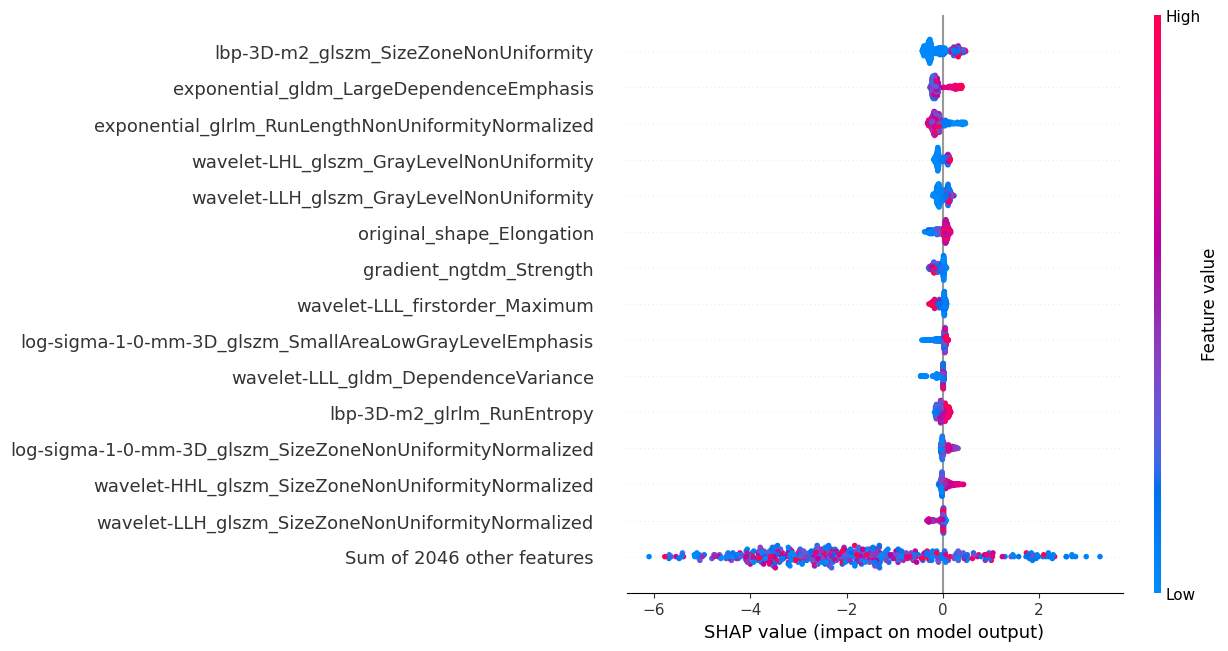

In [34]:
import numpy as np
import pandas as pd
import shap
from src.modeling import load_data, make_model, fit_model
from src.binary_evaluation import calibration_splits, positive_score
from src.radiomics_extraction import load_paths

paths = load_paths(ROOT / "configs/paths.yaml")
lndb, features = load_data(
    ROOT / "data/lndb_ge3_segmentation_3d_c50_hu.csv", "lndb",
    targets_path=paths["lndb"]["segmentation_targets"],
    paths=paths, binary=True, exclude_duplicate_lndb=True,
)
lidc, _ = load_data(
    ROOT / "data/lidc_segmentation_3d_c50_hu.csv",
    "lidc", paths=paths, binary=True,
)

keys = ["LNDbID", "FindingID"]
saved = pd.read_csv(
    ROOT / "models/segmentation_binary_calibration/validation_predictions.csv"
)
saved = saved.loc[
    saved["model"].eq("Binary XGBoost, all features")
].set_index(keys)

parts = []
for fold, _, training, _, test in calibration_splits(lndb):
    train = pd.concat([lidc, lndb.loc[training]], ignore_index=True)
    held_out = lndb.loc[test]
    model = make_model("balanced", model_kind="xgboost", binary=True)
    fit_model(model, train[features], train["target_binary_mean"], "balanced", 0)

    index = pd.MultiIndex.from_frame(held_out[keys])
    np.testing.assert_allclose(
        positive_score(model, held_out[features]),
        saved.loc[index, "score"], rtol=1e-5, atol=1e-7,
    )

    values = pd.DataFrame(
        model[:-1].transform(held_out[features]), columns=features,
    )
    explainer = shap.TreeExplainer(
        model.named_steps["xgbclassifier"],
        feature_perturbation="tree_path_dependent",
    )
    parts.append(explainer(values))
    print(f"Fold {fold} completed")

global_shap = shap.Explanation(
    values=np.concatenate([part.values for part in parts]),
    base_values=np.concatenate([part.base_values for part in parts]),
    data=np.concatenate([part.data for part in parts]),
    feature_names=features,
)
assert len(global_shap.values) == 459
shap.plots.beeswarm(global_shap, max_display=15)